DrugBank — база данных лекарственных веществ с химической, фармакологической и фармацевтической информацией, созданной при поддержке
 University of Alberta.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import importlib

In [2]:
from pathlib import Path
import sys

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))


In [3]:
df = pd.read_csv(project_root / "drugbank.csv")

In [4]:
#Рассмотрим статистические показатели на сырых данных
from supporting_functions.data_structure import numericReview


numericReview(df)

,dtype,spaces,number of unique values,mean_value,median_value,std,iqr
column_name,,,,,,,
Unnamed: 0,int64,0,14594,7296.5,7296.5,4213.069249,7296.5
type,str,0,2,<NA>,<NA>,<NA>,<NA>
drugbank_id,str,0,14594,<NA>,<NA>,<NA>,<NA>
name,str,0,14594,<NA>,<NA>,<NA>,<NA>
state,str,5476,3,<NA>,<NA>,<NA>,<NA>
cal_logp,float64,3297,994,1.808705,2.06,2.669337,3.43
cal_logs,float64,3774,288,-3.385928,-3.6,1.738364,2.4
cal_water_solubility,str,3774,4234,<NA>,<NA>,<NA>,<NA>
cal_molecular_weight,float64,3294,9726,388.626904,343.4219,331.690302,198.3001


In [5]:
#Применим эти функции к очищенным данным
df_cleaned = pd.read_csv(project_root / "cleaned_data.csv")

numericReview(df_cleaned)

,dtype,spaces,number of unique values,mean_value,median_value,std,iqr
column_name,,,,,,,
type,str,0,1,<NA>,<NA>,<NA>,<NA>
drugbank_id,str,0,10046,<NA>,<NA>,<NA>,<NA>
name,str,0,10046,<NA>,<NA>,<NA>,<NA>
state,str,2346,3,<NA>,<NA>,<NA>,<NA>
cal_logp,float64,0,907,1.857403,2.09,2.352779,3.33
cal_logs,float64,0,285,-3.36356,-3.6,1.710083,2.4
cal_water_solubility,float64,0,4072,24.297727,0.0889,107.09984,1.9787
cal_molecular_weight,float64,0,8625,384.473216,348.793,237.124451,192.337875
cal_polar_surface_area,float64,0,4183,104.251451,86.575,91.663101,61.625


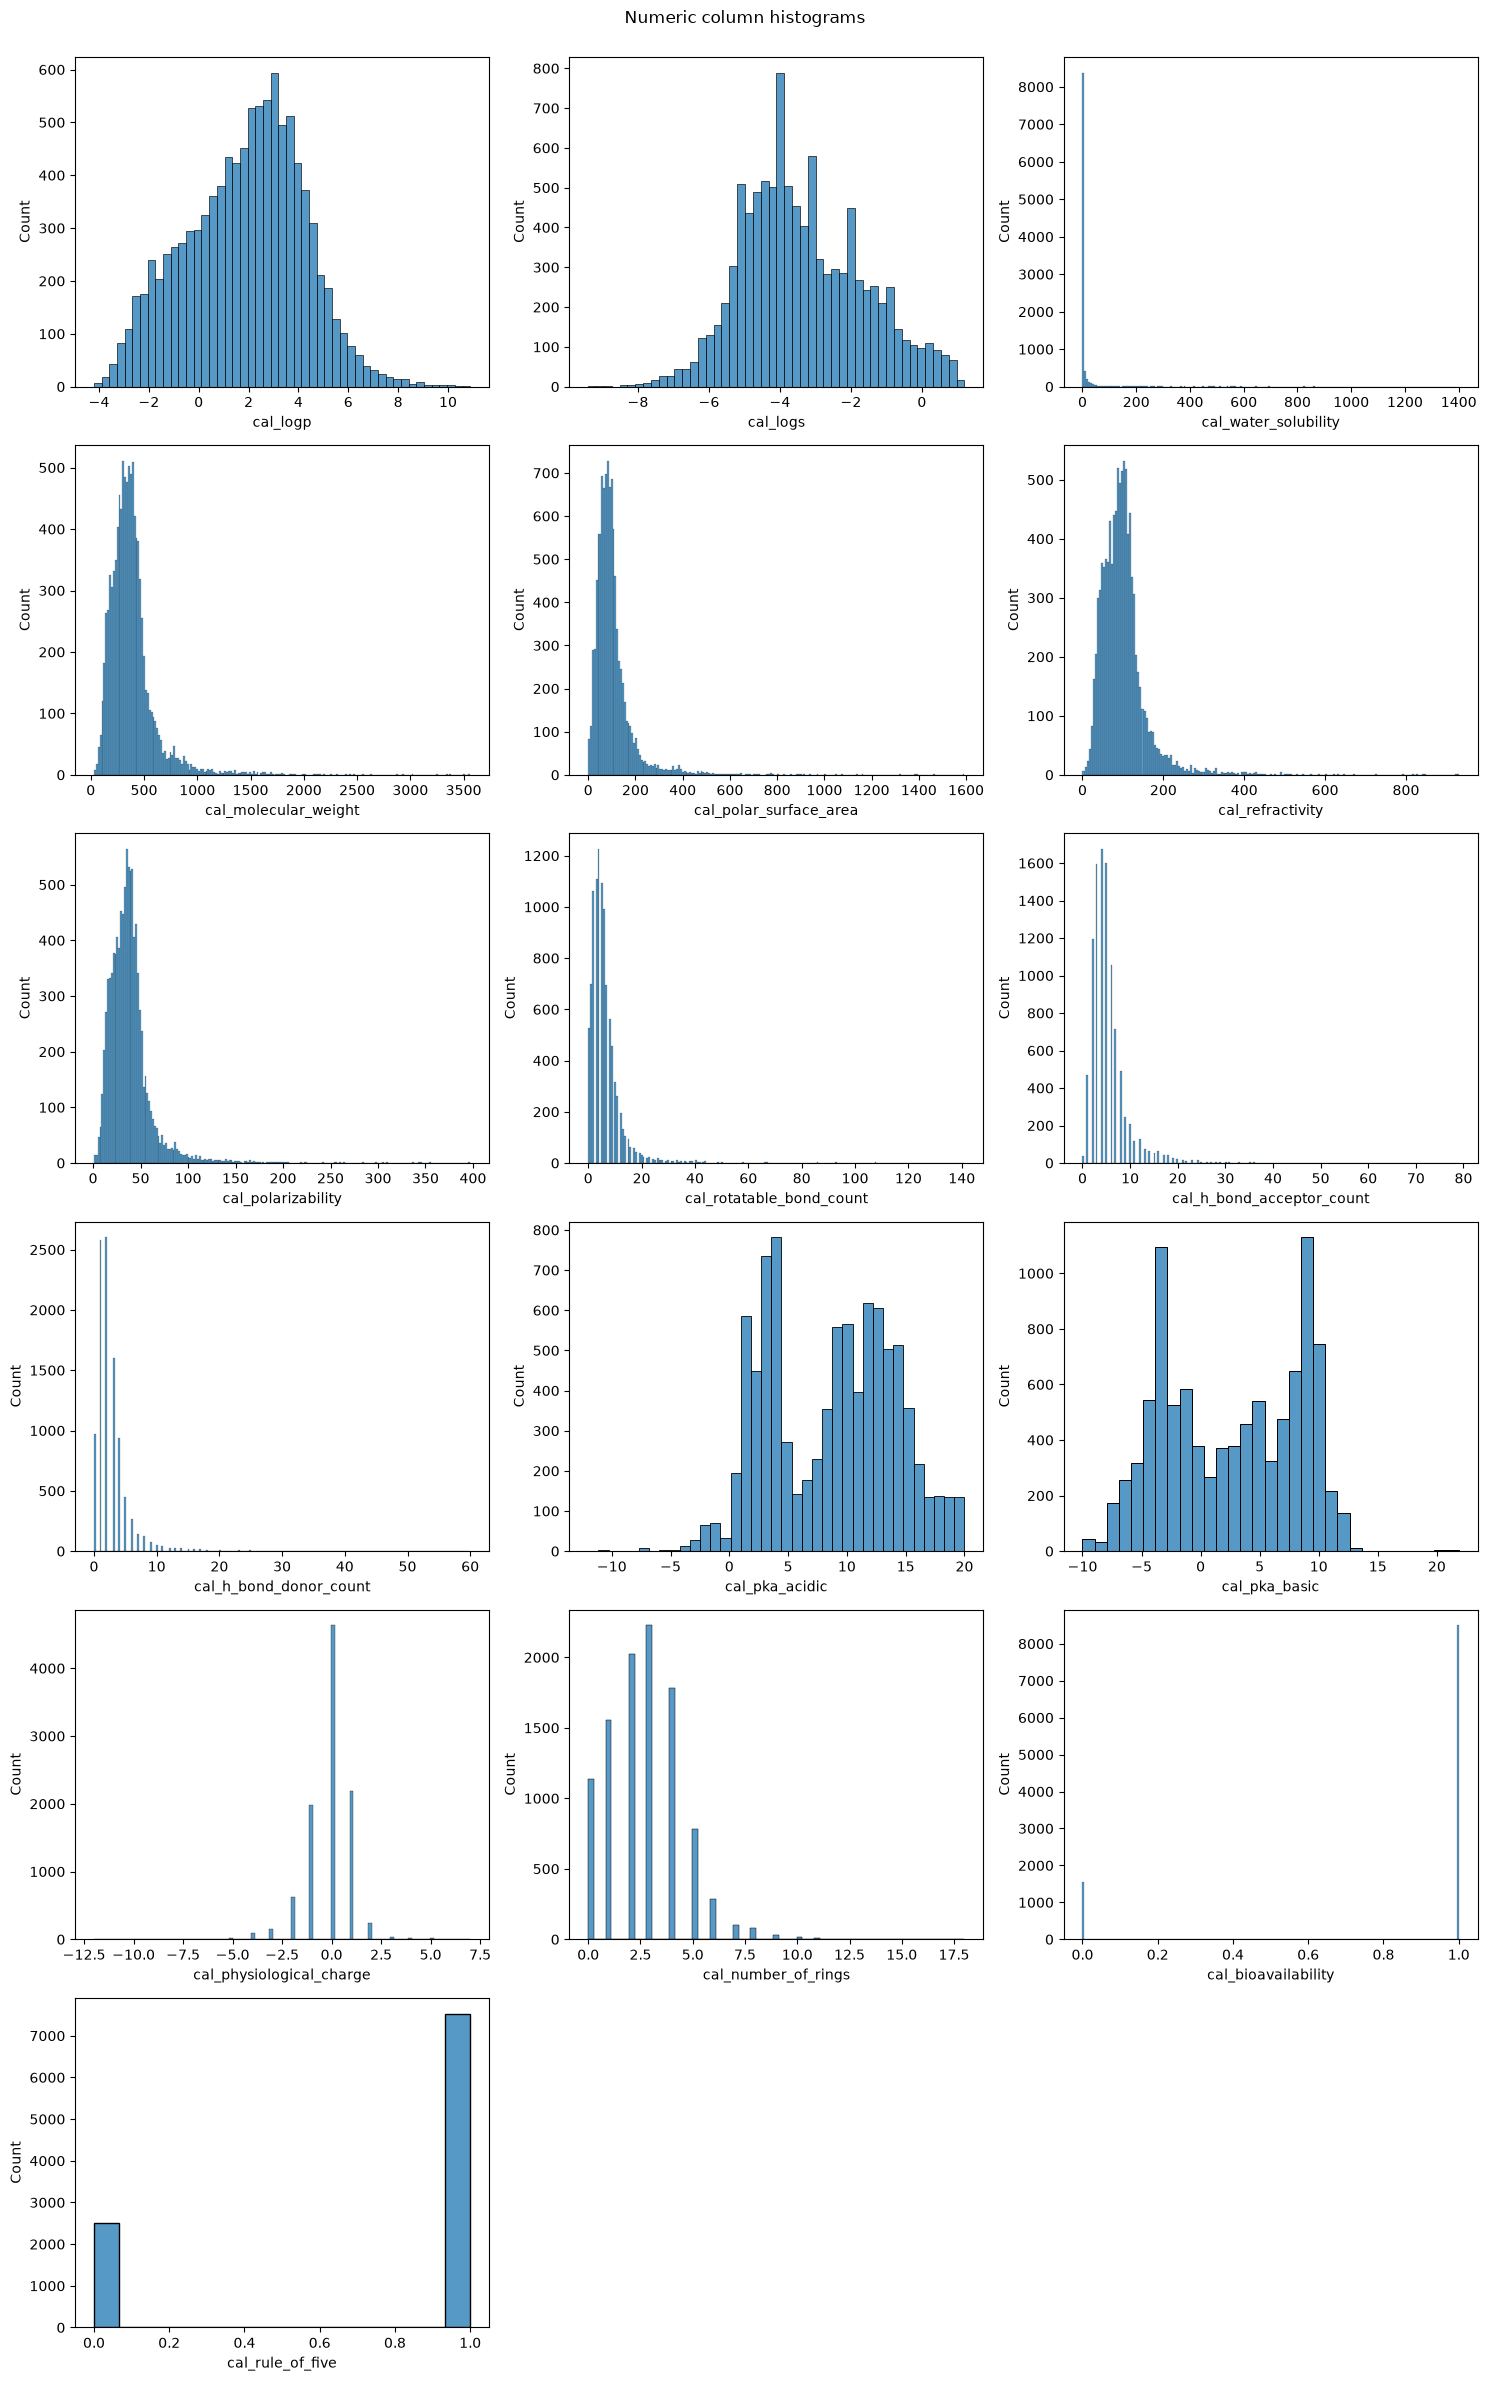

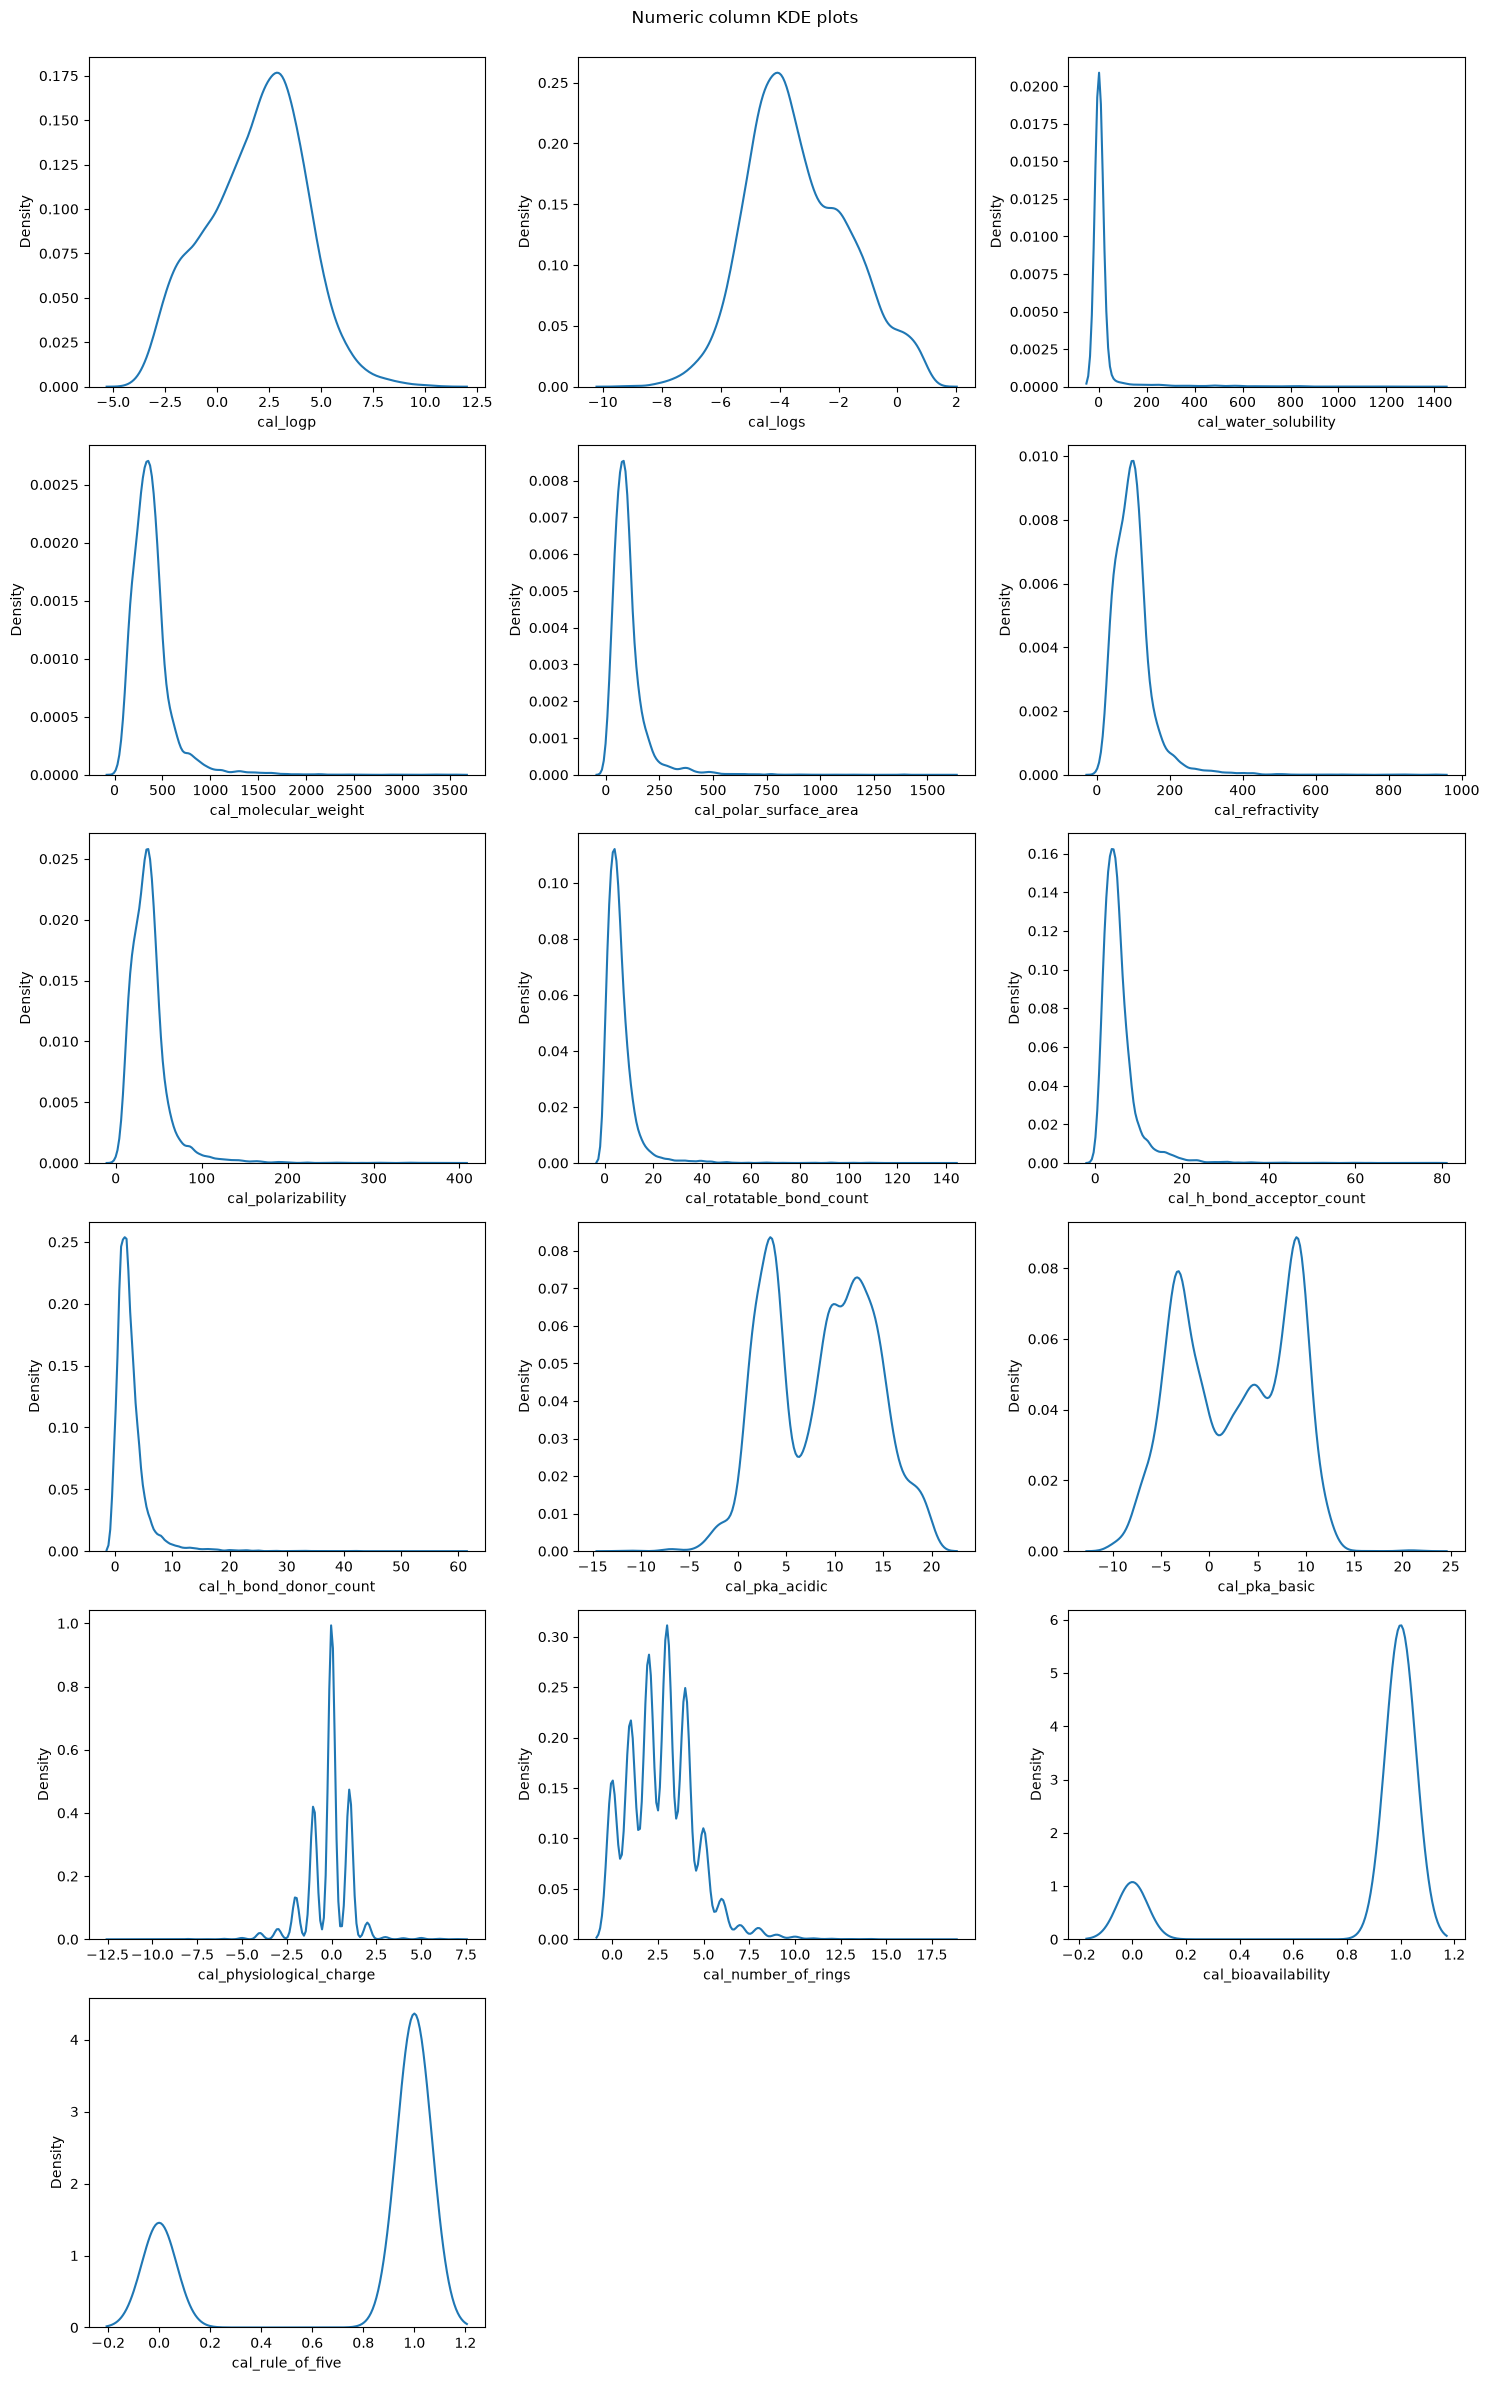

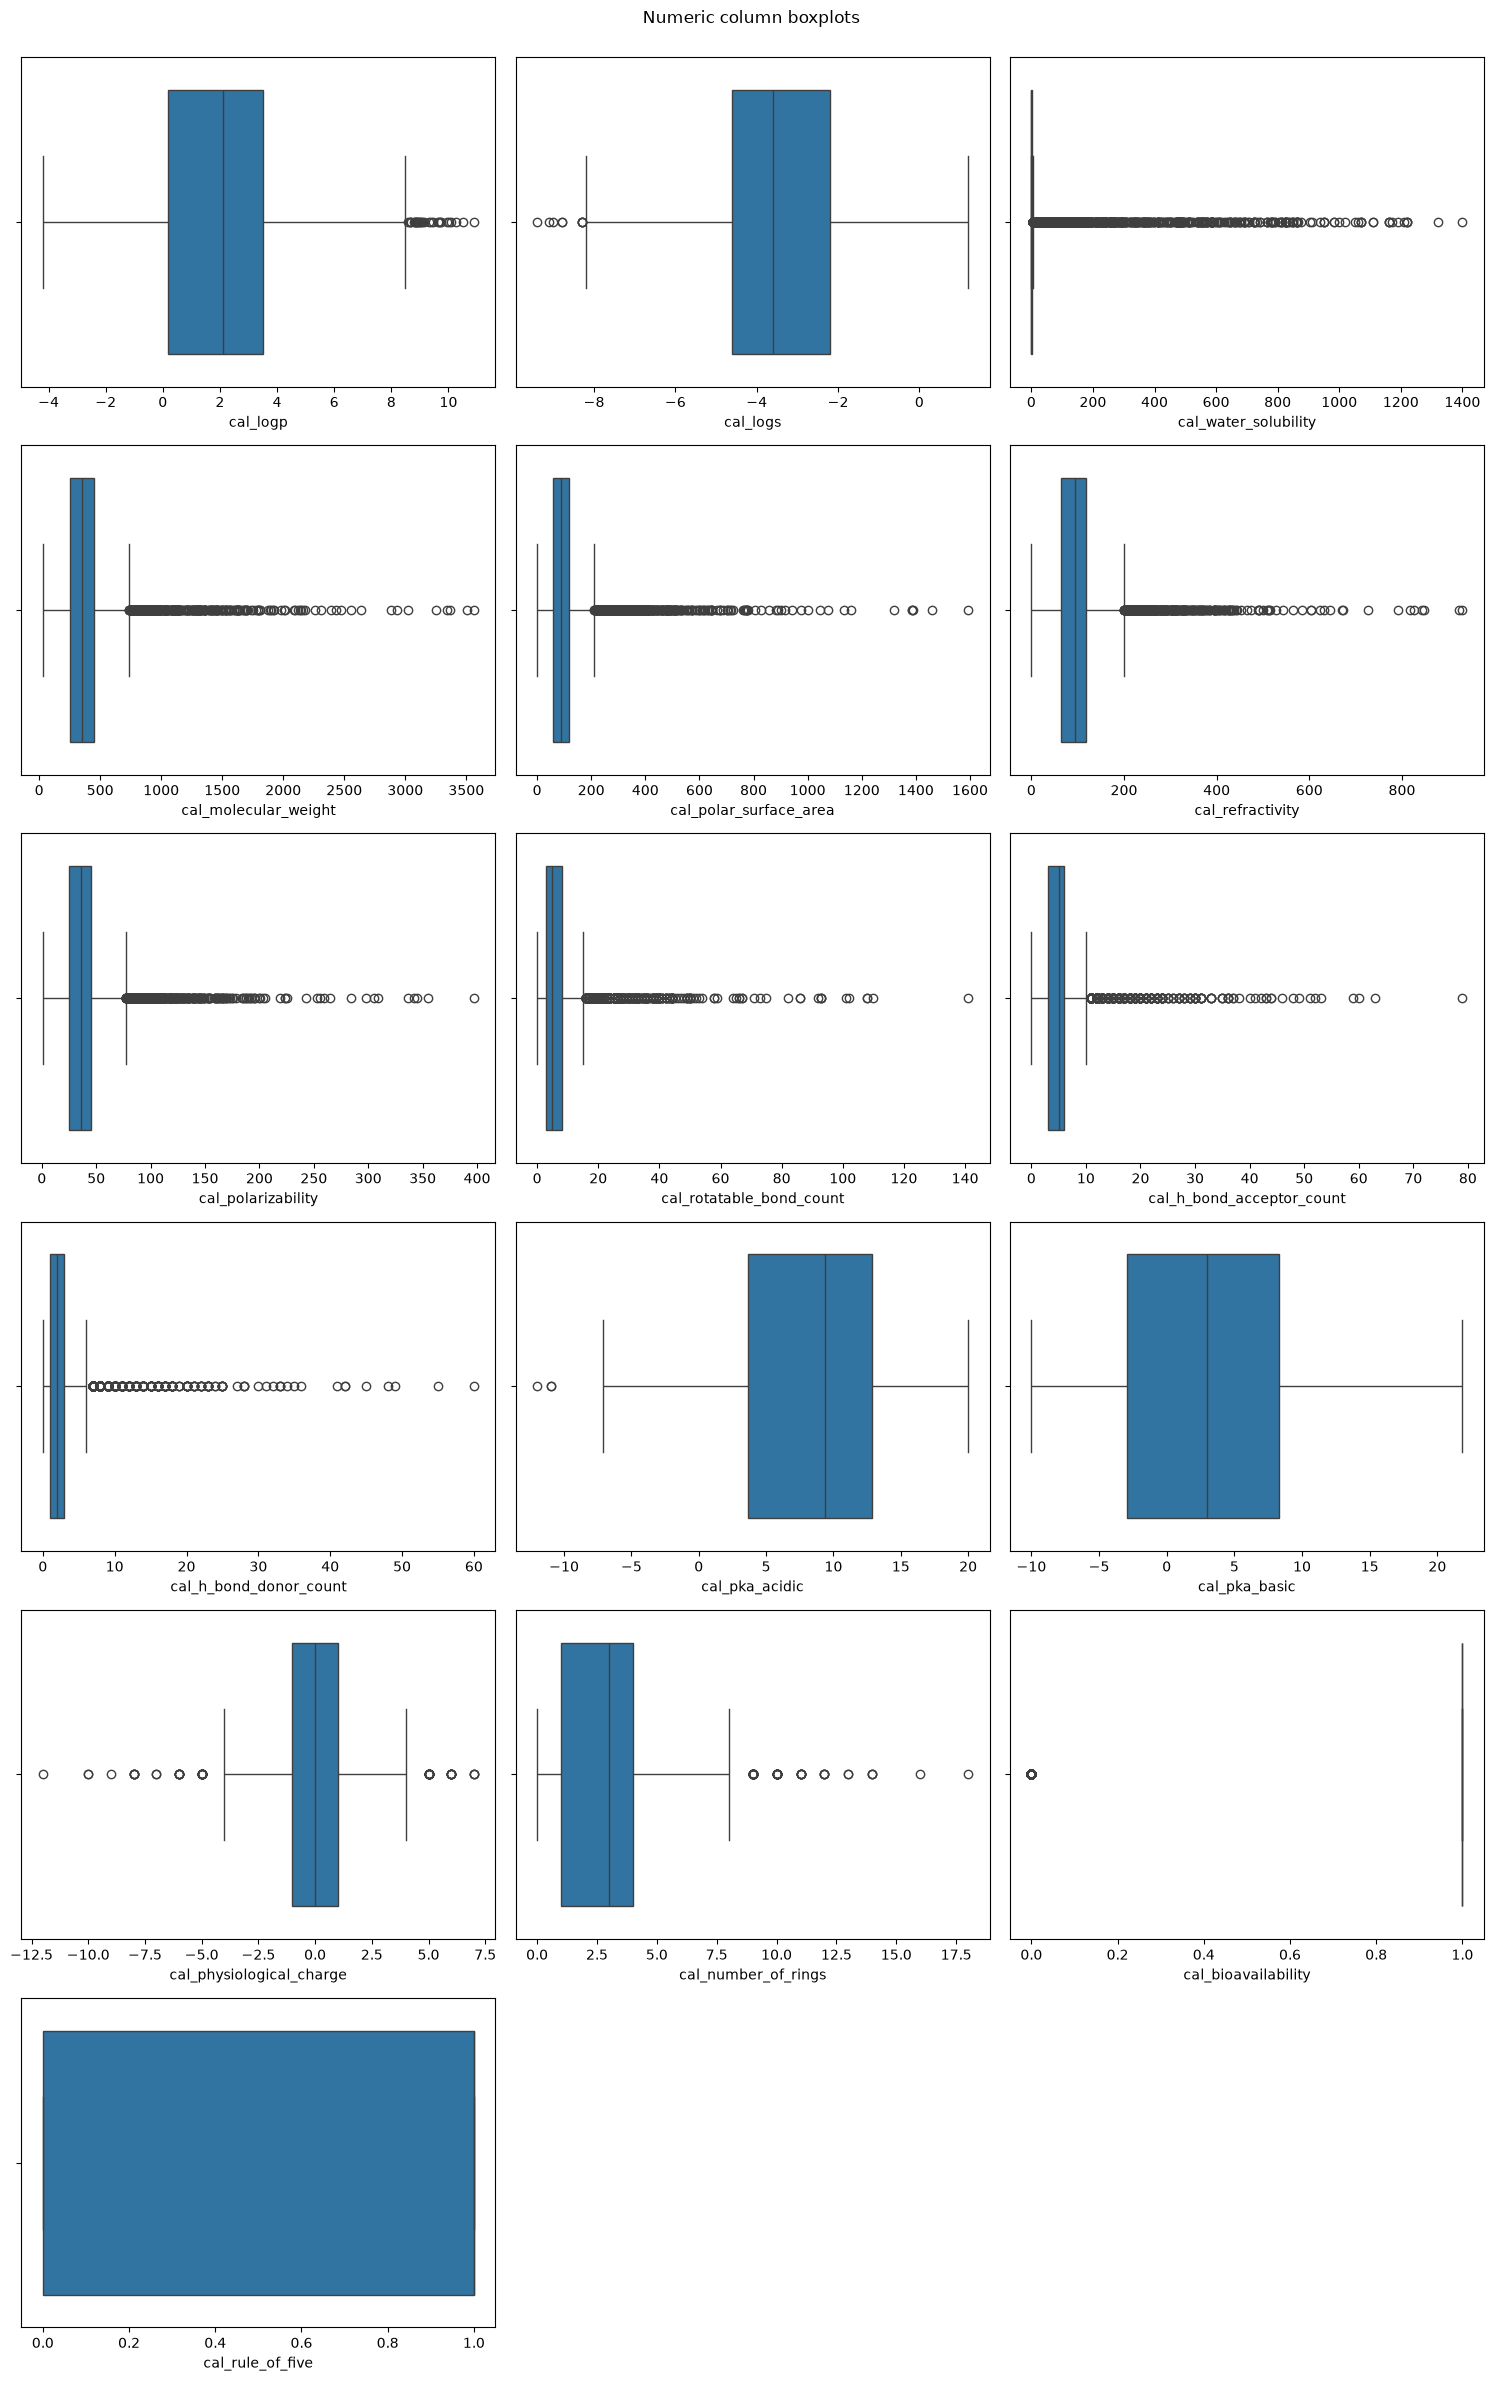

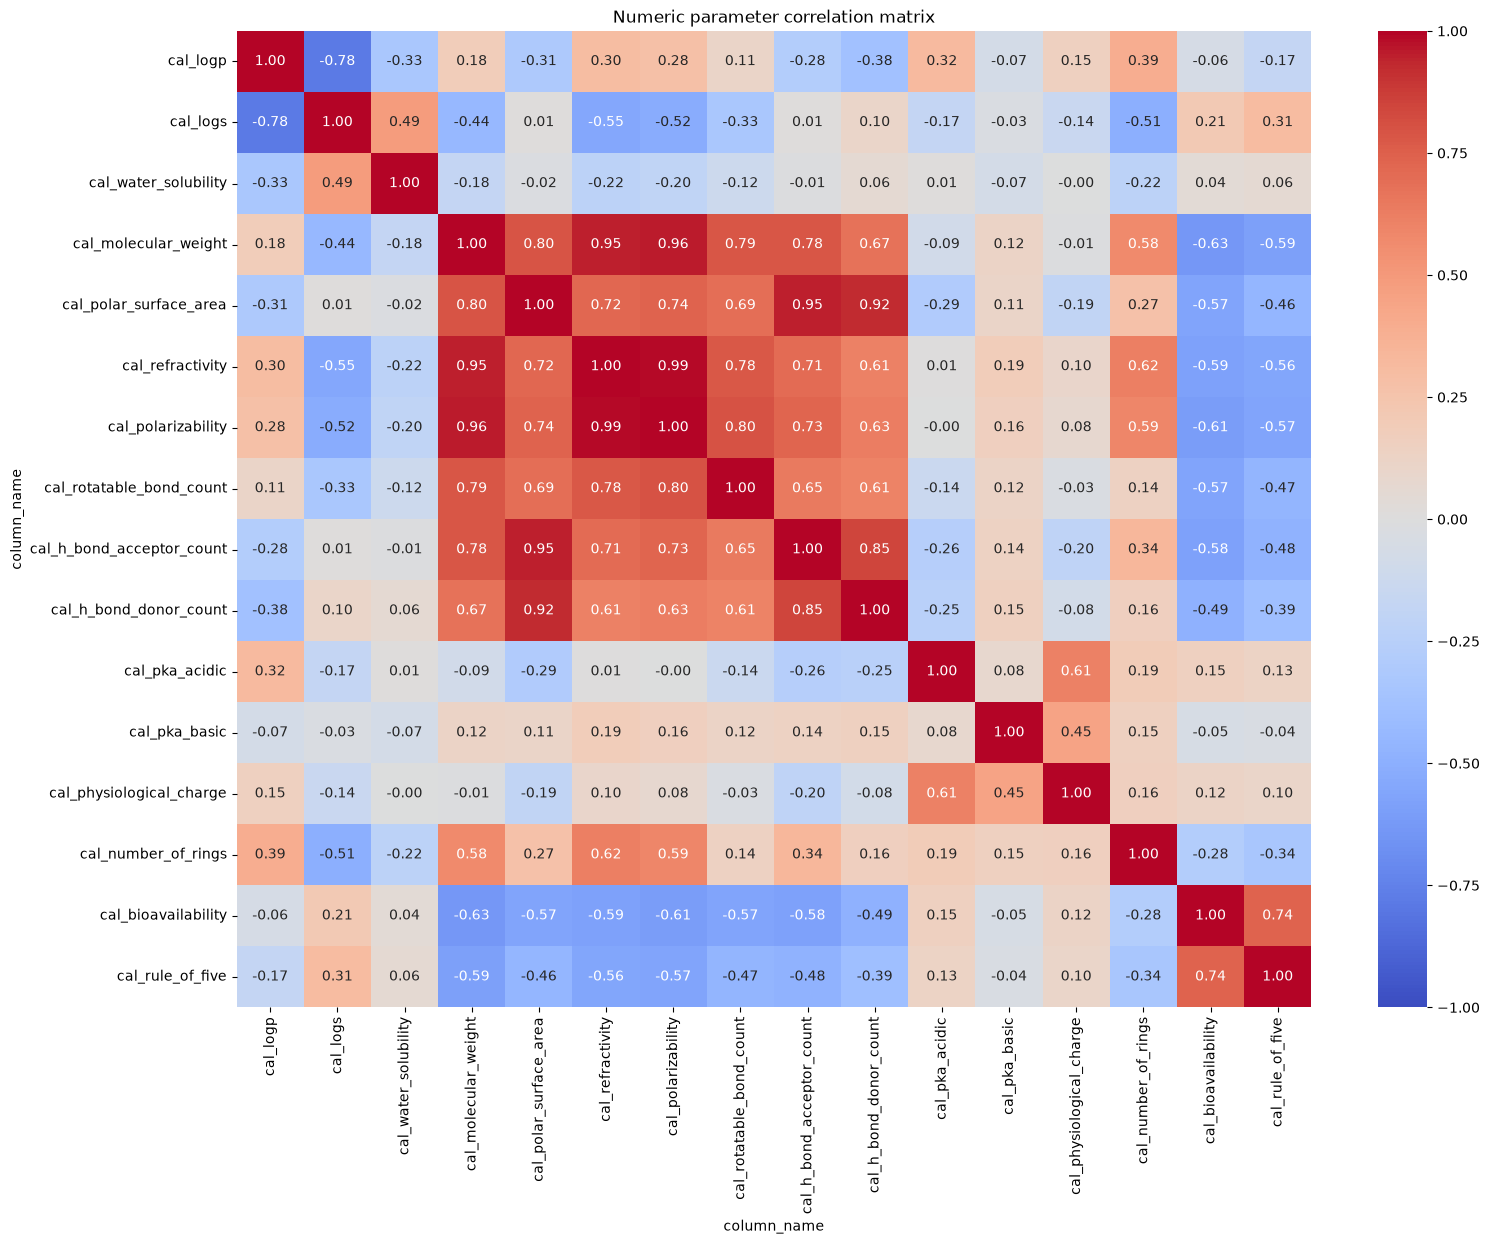

In [6]:
import importlib
import supporting_functions.data_structure as data_structure

importlib.reload(data_structure)

histogram_fig, histogram_axes = data_structure.plot_histograms(df_cleaned)
kde_fig, kde_axes = data_structure.plot_kdes(df_cleaned)
boxplot_fig, boxplot_axes = data_structure.plot_boxplots(df_cleaned)
corr_matrix = data_structure.plot_corr_matrix(df_cleaned)